[![Ouvrir dans Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/philippe-amuzuga/Meca-IA_Ed2026/blob/main/meca-ia/C07/E07-2_Rugosite_Tournage_CORRIGE.ipynb)

# Rugosité d'une surface tournée : prédire dans un tube de tolérance

## Le contexte

En tournage de finition, la rugosité Ra de la surface dépend de l'avance, du rayon de bec de la plaquette, de la vitesse de coupe, de l'usure de la plaquette et de la lubrification. Un service de fabrication a relevé 600 passes de finition. Il voudrait prévoir la rugosité avant d'usiner, pour choisir une avance qui tienne la cote de rugosité du plan. Quelques mesures sont aberrantes, à cause d'un copeau enroulé ou d'une vibration : le modèle ne doit pas s'y accrocher.

La grandeur à prédire est un nombre en µm : c'est un problème de régression.

Défi : prédire `rugosite_Ra_um` et obtenir un R² supérieur à celui du modèle de départ sur la base de test. Ce modèle de départ est une régression à vecteurs de support à noyau linéaire, avec ses réglages par défaut ; il atteint un R² de 0,654 : à vous de faire mieux, en laissant la courbe se plier. La règle de découpage est fixée plus bas. La base de test sert à mesurer, jamais à apprendre ni à régler.

## Les données

Fichier `MecaIA-Rugosite_Tournage.xlsx`, dans le dossier `donnees` du dépôt : 600 passes, 7 colonnes. Une ligne est une passe de finition.

| Colonne | Signification | Unité |
|---|---|---|
| `lubrification` | lubrification : `sec`, `emulsion` ou `huile` | catégorie |
| `vitesse_coupe_m_min` | vitesse de coupe | m/min |
| `avance_mm_tr` | avance par tour | mm/tr |
| `rayon_bec_mm` | rayon de bec de la plaquette : 0,4, 0,8 ou 1,2 | mm |
| `profondeur_passe_mm` | profondeur de passe | mm |
| `usure_VB_mm` | usure en dépouille de la plaquette | mm |
| `rugosite_Ra_um` | cible : rugosité arithmétique Ra mesurée au rugosimètre | µm |

Origine : jeu simulé, d'après la rugosité théorique de tournage, qui croît comme le carré de l'avance et décroît avec le rayon de bec, avec l'usure et l'arête rapportée. Quelques mesures sont aberrantes, et quelques usures et profondeurs de passe ne sont pas relevées. Il enseigne une méthode, et aucune conclusion d'usinage n'en découle.

### Étape 1 : charger le fichier et regarder sa forme

On lit le classeur, puis on vérifie ses dimensions, ses cases vides et la plage de la cible avant toute modélisation : la forme d'un fichier se lit sur le fichier entier. Le dossier des données est cherché depuis le dossier du notebook, puis depuis un clone du dépôt ; ouvert seul, par exemple dans Colab, le notebook télécharge une fois le jeu depuis le dépôt public.

In [1]:
from pathlib import Path
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn import set_config

set_config(display="text")
GRAINE = 42
FICHIER = "MecaIA-Rugosite_Tournage.xlsx"
URL_JEU = "https://raw.githubusercontent.com/philippe-amuzuga/Meca-IA_Ed2026/main/donnees/MecaIA-Rugosite_Tournage.xlsx"

# Le dossier `donnees` du dépôt, cherché depuis le dossier du notebook, puis depuis un clone.
candidats = [Path("..", "..", "donnees"), Path("Meca-IA_Ed2026", "donnees")]
dossier = next((d for d in candidats if (d / FICHIER).is_file()), None)
if dossier is None:
    # Notebook ouvert seul (Colab) : copie unique du jeu depuis le dépôt public.
    dossier = Path("donnees")
    dossier.mkdir(exist_ok=True)
    try:
        urllib.request.urlretrieve(URL_JEU, dossier / FICHIER)
    except OSError as erreur:
        raise FileNotFoundError(
            "Jeu introuvable : clonez le dépôt, ou vérifiez la connexion pour le télécharger.") from erreur
df = pd.read_excel(dossier / FICHIER)

cible = "rugosite_Ra_um"
categories = ["lubrification"]
mesures = ["vitesse_coupe_m_min", "avance_mm_tr", "rayon_bec_mm", "profondeur_passe_mm", "usure_VB_mm"]
print("dimensions :", df.shape)
vides = df.isna().sum()
print("cases vides :", vides[vides > 0].to_dict())
print(df[cible].describe().round(2).to_dict())
df.head(3)

dimensions : (600, 7)
cases vides : {'profondeur_passe_mm': 12, 'usure_VB_mm': 23}
{'count': 600.0, 'mean': 1.27, 'std': 1.29, 'min': 0.18, '25%': 0.47, '50%': 0.76, '75%': 1.47, 'max': 7.45}


,lubrification,vitesse_coupe_m_min,avance_mm_tr,rayon_bec_mm,profondeur_passe_mm,usure_VB_mm,rugosite_Ra_um
0,emulsion,241,0.233,1.2,2.11,0.30,1.38
1,huile,285,0.212,0.8,0.28,0.31,1.32
2,sec,387,0.127,1.2,0.25,0.01,0.45


Lecture du résultat : 600 passes, 7 colonnes. L'usure compte 23 cases vides et la profondeur de passe 12, qu'il faudra remplir. La rugosité va de 0,18 à 7,45 µm, pour une médiane de 0,76 µm : la distribution est étalée vers les grandes valeurs.

### Préparation du dépôt (Colab)

Ouvert seul dans Colab, ce notebook ne voit pas le dossier `donnees/` du dépôt. La cellule suivante ne télécharge rien : elle cherche ce dossier (à deux dossiers au-dessus du notebook, à côté de lui ou dans un clone nommé `Meca-IA_Ed2026`), vérifie la présence du classeur du défi et, sur Colab, liste ce qui manque. Pour le fournir, ouvrez le panneau des fichiers de Colab, créez le dossier `donnees` à la racine de l'espace de travail et téléversez-y le classeur listé, pris dans le dépôt.

In [ ]:
# Préparation du dépôt (utile sur Colab) : cette cellule ne télécharge rien.
import os
from pathlib import Path

JEUX_LUS = ["MecaIA-Rugosite_Tournage.xlsx"]                  # le classeur lu par ce notebook


def chercher(dossier):
    """Le dossier du dépôt cherché depuis le notebook, puis depuis un clone ; None s'il est introuvable."""
    for base in (Path("..", ".."), Path("."), Path("Meca-IA_Ed2026")):
        if (base / dossier).is_dir():
            return base / dossier
    return None


donnees = chercher("donnees")
manque = [f"donnees/{nom}" for nom in JEUX_LUS if donnees is None or not (donnees / nom).is_file()]
if manque and "COLAB_RELEASE_TAG" in os.environ:          # variable posée par Colab
    print("À téléverser dans l'espace de travail de Colab, panneau des fichiers :")
    print("\n".join("  " + nom for nom in manque))


### Étape 2 : mettre le test de côté

Un quart des passes est mis de côté avant tout apprentissage, tout réglage et toute comparaison avec la cible. La graine 42 fixe le tirage : chacun obtient la même base de test, et les scores se comparent.

In [2]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=cible)
y = df[cible]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=GRAINE)
print("apprentissage :", len(X_train), "passes")
print("test :", len(X_test), "passes")

apprentissage : 450 passes
test : 150 passes


### Étape 3 : regarder la rugosité contre l'avance sur l'apprentissage

La figure place la rugosité des passes d'apprentissage selon l'avance, avec un symbole par rayon de bec.

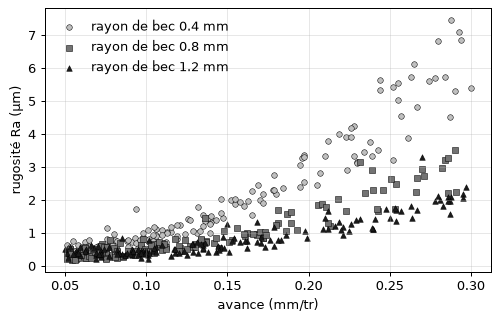

In [3]:
fig, ax = plt.subplots(figsize=(6.4, 3.8))
for rayon, marque, gris in [(0.4, "o", "0.75"), (0.8, "s", "0.45"), (1.2, "^", "0.1")]:
    choix = X_train["rayon_bec_mm"] == rayon
    ax.scatter(X_train.loc[choix, "avance_mm_tr"], y_train[choix], s=20, marker=marque, color=gris,
               edgecolor="black", linewidth=0.4, label=f"rayon de bec {rayon} mm")
ax.set(xlabel="avance (mm/tr)", ylabel="rugosité Ra (µm)")
ax.legend(frameon=False, loc="upper left")
ax.grid(alpha=0.3)
plt.show()

Lecture du résultat : la rugosité ne croît pas proportionnellement à l'avance : elle reste basse aux faibles avances, puis grimpe de plus en plus vite, et d'autant plus que le rayon de bec est petit. La relation est courbe et dépend du rayon : une droite ne pourra pas la suivre. Quelques points s'écartent nettement de leur courbe : ce sont sans doute les mesures aberrantes.

### Étape 4 : construire le modèle de départ

Le modèle de départ est celui de la section du livre : une régression à vecteurs de support, qui ajuste une fonction en acceptant, autour d'elle, un tube de tolérance de demi-largeur `epsilon` dans lequel les écarts ne coûtent rien. Avec un noyau linéaire, la fonction est une droite, un plan ici. Un pipeline encode la lubrification en colonnes 0 ou 1, remplit les cases vides par la médiane de l'apprentissage et met les mesures à l'échelle. Il apprend sur `X_train` seul.

In [4]:
# Solution :
from sklearn.compose import make_column_transformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVR

preprocessor = make_column_transformer(
    (OneHotEncoder(), categories),
    (make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), mesures))
modele = make_pipeline(preprocessor, SVR(kernel="linear"))
modele.fit(X_train, y_train)
# Fin de la solution

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('onehotencoder',
                                                  OneHotEncoder(),
                                                  ['lubrification']),
                                                 ('pipeline',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('standardscaler',
                                                                   StandardScaler())]),
                                                  ['vitesse_coupe_m_min',
                                                   'avance_mm_tr',
                                                   'rayon_bec_mm',
                                                   'profondeur_passe_mm',
                                                   'usu

### Étape 5 : mesurer sur la base de test

Le modèle prédit les passes qu'il n'a jamais vues. Trois indicateurs sont lus : le coefficient de détermination R², et deux erreurs en µm, la racine de l'erreur quadratique moyenne (RMSE) et l'erreur absolue moyenne (MAE). Un témoin sans apprentissage, qui répond toujours la moyenne de l'apprentissage, donne le point de comparaison le plus bas.

In [5]:
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error

y_pred = modele.predict(X_test)
score_depart = r2_score(y_test, y_pred)
score_temoin = r2_score(y_test, np.full(len(y_test), y_train.mean()))
print(f"R² : {score_depart:.3f}")
print(f"RMSE : {root_mean_squared_error(y_test, y_pred):.2f} µm")
print(f"MAE : {mean_absolute_error(y_test, y_pred):.2f} µm")
print(f"R² du témoin (toujours la moyenne de l'apprentissage) : {score_temoin:.3f}")
print(f"points d'appui hors du tube : {len(modele[-1].support_)} sur {len(X_train)} passes")

R² : 0.654
RMSE : 0.78 µm
MAE : 0.42 µm
R² du témoin (toujours la moyenne de l'apprentissage) : -0.000
points d'appui hors du tube : 339 sur 450 passes


Lecture du résultat : le R² est de 0,654 et l'erreur absolue moyenne de 0,42 µm, pour une rugosité moyenne de 1,28 µm sur la base de test. Le témoin, qui répond toujours la moyenne, n'explique rien : son R² est nul, au signe de l'arrondi près. La droite s'appuie sur 339 passes sur 450 : presque toutes sortent du tube, puisqu'une droite ne suit pas la courbe de l'étape 3. C'est ce chiffre, mesuré sur des passes que le modèle n'a jamais vues, que l'on a le droit d'annoncer.

## Pour aller plus loin : un noyau gaussien, puis régler C, epsilon et gamma

Le modèle de départ de l'étape 4 reste le score de référence du défi. Les deux cellules suivantes montrent comment le dépasser sans regarder le test pour choisir. La première compare par validation croisée, sur l'apprentissage seul, le noyau linéaire, une régression linéaire ordinaire, le noyau gaussien aux réglages par défaut, puis le même noyau avec C, epsilon et gamma choisis par une grille, mesurée en validation croisée emboîtée. Un gradient boosting, vu au chapitre 8, est donné pour comparaison seulement. La seconde mesure le modèle retenu une seule fois sur le test. Les valeurs sont lues dans les sorties imprimées.

In [6]:
# Solution :
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GridSearchCV, KFold, cross_val_score

plis = KFold(n_splits=5, shuffle=True, random_state=GRAINE)
grille = GridSearchCV(
    make_pipeline(preprocessor, SVR()),
    param_grid={"svr__C": [1, 10, 100], "svr__epsilon": [0.01, 0.05, 0.1], "svr__gamma": [0.03, 0.1, 0.3]},
    cv=5, scoring="r2")
candidats = {
    "départ : noyau linéaire": modele,
    "régression linéaire ordinaire": make_pipeline(preprocessor, LinearRegression()),
    "noyau gaussien, réglages par défaut": make_pipeline(preprocessor, SVR()),
    "noyau gaussien, C, epsilon et gamma par grille": grille}
notes_cv, ecarts_cv = {}, {}
for nom, pipeline in candidats.items():
    notes = cross_val_score(pipeline, X_train, y_train, cv=plis, scoring="r2")
    notes_cv[nom], ecarts_cv[nom] = notes.mean(), notes.std()
    print(f"{nom} : R² {notes.mean():.3f} +/- {notes.std():.3f} sur 5 plis")
nom_retenu = max(notes_cv, key=notes_cv.get)
print("modèle retenu par la validation croisée :", nom_retenu)
boosting = make_pipeline(preprocessor, HistGradientBoostingRegressor(random_state=GRAINE))
notes = cross_val_score(boosting, X_train, y_train, cv=plis, scoring="r2")
print(f"pour comparaison, gradient boosting (chapitre 8) : R² {notes.mean():.3f} +/- {notes.std():.3f} sur 5 plis")
# Fin de la solution

départ : noyau linéaire : R² 0.660 +/- 0.045 sur 5 plis
régression linéaire ordinaire : R² 0.741 +/- 0.033 sur 5 plis
noyau gaussien, réglages par défaut : R² 0.923 +/- 0.027 sur 5 plis
noyau gaussien, C, epsilon et gamma par grille : R² 0.978 +/- 0.010 sur 5 plis
modèle retenu par la validation croisée : noyau gaussien, C, epsilon et gamma par grille
pour comparaison, gradient boosting (chapitre 8) : R² 0.948 +/- 0.027 sur 5 plis


In [7]:
# Solution :
retenu = candidats[nom_retenu].fit(X_train, y_train)
r2_retenu = r2_score(y_test, retenu.predict(X_test))
print(f"{nom_retenu}, mesuré une fois sur le test : R² {r2_retenu:.3f}")
print(f"gain sur le modèle de départ : {r2_retenu - score_depart:+.3f}")
if hasattr(retenu, "best_params_"):
    print("réglages choisis par la grille :", retenu.best_params_)
    bornes = [p for p, valeur in retenu.best_params_.items()
              if valeur in (min(grille.param_grid[p]), max(grille.param_grid[p]))]
    print("réglages au bord de la grille :", bornes, "(une grille plus large les confirmerait)")
# Fin de la solution

noyau gaussien, C, epsilon et gamma par grille, mesuré une fois sur le test : R² 0.973
gain sur le modèle de départ : +0.319
réglages choisis par la grille : {'svr__C': 100, 'svr__epsilon': 0.01, 'svr__gamma': 0.03}
réglages au bord de la grille : ['svr__C', 'svr__epsilon', 'svr__gamma'] (une grille plus large les confirmerait)


## Le score de référence

Le score publié est le R² du modèle de départ de l'étape 4 sur la base de test. L'empreinte identifie cette base de test : si la vôtre diffère, le découpage n'est pas le même et les scores ne se comparent pas.

In [8]:
import hashlib

score = r2_score(y_test, modele.predict(X_test))
positions = ",".join(str(i) for i in sorted(X_test.index))
print("EMPREINTE_TEST =", hashlib.sha256(positions.encode("ascii")).hexdigest())
print("SCORE_REFERENCE r2 = %.3f" % score)

EMPREINTE_TEST = a7ca49e52de6d732f650852483129553cafeeb4461fe00f368065f8bc4e2d630
SCORE_REFERENCE r2 = 0.654


## Synthèse

1. Une régression à vecteurs de support ajuste une fonction en laissant un tube de demi-largeur epsilon autour d'elle : les écarts dans le tube ne coûtent rien, et seuls les points hors du tube, les vecteurs de support, fixent le modèle.
2. Avec un noyau linéaire, la fonction est un plan : elle ne suit pas une rugosité qui croît comme le carré de l'avance. En validation croisée, la droite à tube donne un R² de 0,660 et le noyau gaussien aux réglages par défaut 0,923.
3. Le noyau gaussien se règle par C, qui arbitre la marge et les erreurs, par epsilon, la largeur du tube, et par gamma, la portée de chaque point ; une grille les choisit, et sa mesure fiable est une validation croisée emboîtée.
4. Les mesures se mettent à l'échelle avant tout noyau, sur l'apprentissage seul.
5. Le choix du modèle se fait par validation croisée sur l'apprentissage ; le test ne sert qu'une fois, au modèle retenu.